# E2-v2: CMX + CMRF on PST900 (resumable Colab run) · Team 41
**How to run:** Runtime → Change runtime type → **T4 GPU**, then **Run all**.
Stop any time (or lose the connection): run all cells again and training continues from the last finished epoch.

What is saved in `MyDrive/AIProj_CMX/runs/<experiment>/`:
* `last.pth`: model + optimizer + epoch, rewritten after **every** epoch (this is what resume uses)
* `best_model.pth`: the epoch with the **lowest validation loss** so far, checked after every epoch
* `epoch_10.pth, epoch_20.pth, ... epoch_100.pth`: a copy of the model every 10 epochs
* `train_log.csv`: train loss, validation loss and validation mIoU for every epoch

The same notebook also runs E1 / E3 / Control: change `EXPERIMENT` in Cell 1.

In [1]:
# ==========================================
# CELL 1: Environment, GPU check, experiment choice
# ==========================================
import os
import sys
import torch

print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")
if torch.cuda.is_available():
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"Assigned GPU: {torch.cuda.get_device_name(0)} ({vram_gb:.2f} GB VRAM)")
else:
    raise SystemError("GPU not detected! Go to Runtime -> Change runtime type -> Select T4 GPU.")

# ---------------- choose the experiment ----------------
#   'E2v2'    : CMX + CMRF at stage 3 (fixed version of E2)          <- run this now
#   'E1'      : plain CMX, same pipeline (fair baseline for E2v2/E3: same split, same training code)
#   'E3'      : E2v2 + modality-specific corruption during training
#   'CONTROL' : E1 + the same corruption training, without CMRF
EXPERIMENT = 'E2v2'

EXPERIMENTS = {
    'E2v2':    dict(cmrf_stages=[3], corruption_p=0.0),
    'E1':      dict(cmrf_stages=[],  corruption_p=0.0),
    'E3':      dict(cmrf_stages=[3], corruption_p=0.5),
    'CONTROL': dict(cmrf_stages=[],  corruption_p=0.5),
}
SETTINGS = EXPERIMENTS[EXPERIMENT]
RUN_NAME = f"{EXPERIMENT}_cmx_b2_ep100"

# ---------------- paths ----------------
WORKSPACE   = "/content/CMX_PST900_Workspace"                 # fast local disk (lost when the runtime ends)
REPO_DIR    = os.path.join(WORKSPACE, "RGBX_Semantic_Segmentation")
DATASET_DIR = os.path.join(WORKSPACE, "datasets")
DRIVE_ROOT  = "/content/drive/MyDrive/AIProj_CMX"              # Google Drive (kept forever)
CKPT_DIR    = os.path.join(DRIVE_ROOT, "runs", RUN_NAME)        # checkpoints of THIS experiment
RESULTS_DIR = os.path.join(CKPT_DIR, "results")
SPLIT_JSON  = os.path.join(DRIVE_ROOT, "runs", "val_split.json")  # shared by every experiment

from google.colab import drive
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

for d in (WORKSPACE, DATASET_DIR, CKPT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)
os.chdir(WORKSPACE)
print(f"Experiment: {EXPERIMENT} -> {SETTINGS}")
print(f"Checkpoints (Drive): {CKPT_DIR}")
print("Existing files:", sorted(os.listdir(CKPT_DIR)) or "none (fresh run)")


Python Version: 3.13.16
PyTorch Version: 2.14.1+cu130
Assigned GPU: Tesla T4 (14.56 GB VRAM)
Mounted at /content/drive
Experiment: E2v2 -> {'cmrf_stages': [3], 'corruption_p': 0.0}
Checkpoints (Drive): /content/drive/MyDrive/AIProj_CMX/runs/E2v2_cmx_b2_ep100
Existing files: ['best_model.pth', 'epoch_10.pth', 'epoch_100.pth', 'epoch_20.pth', 'epoch_30.pth', 'epoch_40.pth', 'epoch_50.pth', 'epoch_60.pth', 'epoch_70.pth', 'epoch_80.pth', 'epoch_90.pth', 'last.pth', 'results', 'run_config.json', 'train_log.csv']


In [2]:
# ==========================================
# CELL 2: Clone Official CMX Repo & Dependencies
# ==========================================
if not os.path.exists(REPO_DIR):
    !git clone -q https://github.com/huaaaliu/RGBX_Semantic_Segmentation.git {REPO_DIR}
!pip install -q timm==0.6.13 einops easydict yacs tabulate gdown fvcore opencv-python-headless
print("Repo ready:", REPO_DIR)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Repo ready: /content/CMX_PST900_Workspace/RGBX_Semantic_Segmentation


In [3]:
# ==========================================
# CELL 3: Find & Verify Pretrained MiT-B2 (ImageNet)
# ==========================================
import glob
import shutil

PRETRAINED_DIR = os.path.join(WORKSPACE, "pretrained")
MIT_B2 = os.path.join(PRETRAINED_DIR, "mit_b2.pth")
os.makedirs(PRETRAINED_DIR, exist_ok=True)

if not os.path.exists(MIT_B2):
    found = (glob.glob(f"{DRIVE_ROOT}/pretrained/mit_b2.pth") +
             glob.glob("/content/drive/MyDrive/**/mit_b2.pth", recursive=True) +
             glob.glob("/content/drive/.shortcut-targets-by-id/*/**/mit_b2.pth", recursive=True))
    if found:
        print("Copying from Drive:", found[0])
        shutil.copy(found[0], MIT_B2)
    else:
        print("Not in Drive: downloading from the CMX authors' Google-Drive folder ...")
        !gdown --folder https://drive.google.com/drive/folders/10XgSW8f7ghRs9fJ0dE-EV8G2E_guVsT5 -O {PRETRAINED_DIR}/dl
        dl = glob.glob(f"{PRETRAINED_DIR}/dl/**/mit_b2.pth", recursive=True)
        assert dl, "Download failed (Drive quota). Put mit_b2.pth in MyDrive/AIProj_CMX/pretrained/ and re-run."
        shutil.copy(dl[0], MIT_B2)
        os.makedirs(f"{DRIVE_ROOT}/pretrained", exist_ok=True)
        shutil.copy(MIT_B2, f"{DRIVE_ROOT}/pretrained/mit_b2.pth")   # keep a copy for next time

sd = torch.load(MIT_B2, map_location="cpu", weights_only=False)
sd = sd.get("model", sd.get("state_dict", sd))
assert "patch_embed1.proj.weight" in sd, "This file is not a MiT (SegFormer) checkpoint."
print(f"MiT-B2 OK: {len(sd)} tensors, {os.path.getsize(MIT_B2)/1e6:.0f} MB")
del sd


Copying from Drive: /content/drive/MyDrive/AIProj_CMX/pretrained/mit_b2.pth
MiT-B2 OK: 334 tensors, 99 MB


In [4]:
# ==========================================
# CELL 4: Copy PST900 from Drive to the Local SSD
# ==========================================
import zipfile

def find_pst_root(base):
    for p in glob.glob(f"{base}/**/train/rgb", recursive=True):
        root = os.path.dirname(os.path.dirname(p))
        if os.path.isdir(os.path.join(root, "test", "rgb")):
            return root
    return None

PST_ROOT = find_pst_root(DATASET_DIR)
if PST_ROOT is None:
    zips = (glob.glob(f"{DRIVE_ROOT}/datasets/PST900*.zip") + glob.glob("/content/drive/MyDrive/PST900*.zip") +
            glob.glob("/content/drive/MyDrive/*/PST900*.zip") + glob.glob("/content/drive/MyDrive/*/*/PST900*.zip"))
    folders = [os.path.dirname(os.path.dirname(p)) for p in
               glob.glob("/content/drive/MyDrive/*/train/rgb") + glob.glob("/content/drive/MyDrive/*/*/train/rgb") +
               glob.glob("/content/drive/MyDrive/*/*/*/train/rgb")]
    if zips:
        print("Unzipping", zips[0], "to the local SSD (about 1-2 min) ...")
        shutil.copy(zips[0], f"{DATASET_DIR}/pst900.zip")
        with zipfile.ZipFile(f"{DATASET_DIR}/pst900.zip") as z:
            z.extractall(DATASET_DIR)
        os.remove(f"{DATASET_DIR}/pst900.zip")
    elif folders:
        print("Copying folder", folders[0], "to the local SSD ...")
        !cp -r "{folders[0]}" "{DATASET_DIR}/PST900_RGBT_Dataset"
    else:
        print("PST900 not found in Drive: downloading (1.4 GB) ...")
        !gdown 1hZeM-MvdUC_Btyok7mdF00RV-InbAadm -O {DATASET_DIR}/pst900.zip
        assert os.path.exists(f"{DATASET_DIR}/pst900.zip"), \
            "Download failed (Drive quota). Put PST900_RGBT_Dataset.zip in MyDrive/AIProj_CMX/datasets/ and re-run."
        with zipfile.ZipFile(f"{DATASET_DIR}/pst900.zip") as z:
            z.extractall(DATASET_DIR)
        os.remove(f"{DATASET_DIR}/pst900.zip")
    PST_ROOT = find_pst_root(DATASET_DIR)

assert PST_ROOT, "Could not find train/rgb and test/rgb after extraction."
n_train = len(glob.glob(f"{PST_ROOT}/train/rgb/*.png"))
n_test = len(glob.glob(f"{PST_ROOT}/test/rgb/*.png"))
print(f"PST900 at {PST_ROOT}: train {n_train} | test {n_test}")
if (n_train, n_test) != (597, 288):
    print("WARNING: PST900 should have 597 train / 288 test images. Check the dataset before training!")


Unzipping /content/drive/MyDrive/AIProj_CMX/datasets/PST900_RGBT_Dataset.zip to the local SSD (about 1-2 min) ...
PST900 at /content/CMX_PST900_Workspace/datasets/PST900_RGBT_Dataset: train 597 | test 288


In [5]:
%%writefile /content/CMX_PST900_Workspace/rgbt_eval.py
# CELL 5a: Evaluation toolkit (dataset, corruptions, metrics, sliding window, cost)
"""
rgbt_eval.py -- Evaluation toolkit for the CMX / CMRF RGB-Thermal project (PST900)

1. PST900Dataset  : reads images exactly like the official CMX repo (OpenCV;
                    BGR channel order by default), labels at ORIGINAL resolution,
                    out-of-range labels -> 255 (ignored, never clipped into a class),
                    optional seeded corruption hook.
2. Corruptions    : fixed RGB / thermal degradations, 3 severities, global and LOCALIZED.
3. SegMetrics     : confusion-matrix mIoU, Dice, Sensitivity, Specificity
                    (per class / mean over all classes / mean over object classes).
4. evaluate(), run_benchmark(), robustness_summary()
                    sliding-window inference (like the CMX evaluator), clean + corrupted.
5. model_cost()   : params, GFLOPs (fvcore), latency, FPS.
"""

import os
import csv
import glob
import time
import random

import cv2
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

IGNORE_INDEX = 255

# Verify this order against the official PST900 README before reporting results.
PST900_CLASSES = ["Background", "Fire-Extinguisher", "Backpack", "Hand-Drill", "Survivor"]
PST900_PALETTE = [[0, 0, 0], [255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 0]]  # RGB

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])


# =============================================================================
# 1. Corruptions (uint8 numpy; RGB image is HxWx3 in RGB order, thermal HxW)
# =============================================================================
# Keep these FIXED for the whole project so E1-E4 are scored on identical inputs.
SEVERITY = {
    "low_light": [(0.45, 1.5, 4), (0.30, 2.0, 8), (0.15, 2.5, 12)],  # brightness, gamma, noise std
    "noise":     [10, 20, 35],            # gaussian noise std (0-255)
    "blur":      [2.0, 4.0, 7.0],         # gaussian sigma in px (at 720x1280)
    "occlusion": [0.10, 0.20, 0.35],      # fraction of image area covered by patches
}

CORRUPTIONS = {
    "rgb_low_light":     ("rgb", "low_light"),
    "rgb_noise":         ("rgb", "noise"),
    "rgb_blur":          ("rgb", "blur"),
    "rgb_occlusion":     ("rgb", "occlusion"),      # localized
    "thermal_noise":     ("thermal", "noise"),
    "thermal_blur":      ("thermal", "blur"),
    "thermal_occlusion": ("thermal", "occlusion"),  # localized
}


def _gaussian_noise(img, std, rng):
    return np.clip(img.astype(np.float32) + rng.normal(0.0, std, img.shape), 0, 255).astype(np.uint8)


def _blur(img, sigma):
    return cv2.GaussianBlur(img, (0, 0), sigmaX=sigma, sigmaY=sigma)


def _low_light(img, brightness, gamma, noise_std, rng):
    x = np.power((img.astype(np.float32) / 255.0) * brightness, gamma) * 255.0
    x = x + rng.normal(0.0, noise_std, img.shape)
    return np.clip(x, 0, 255).astype(np.uint8)


def _occlusion(img, area_frac, rng, fill="noise"):
    out = img.copy()
    h, w = img.shape[:2]
    n = int(rng.integers(3, 7))
    patch_area = area_frac * h * w / n
    for _ in range(n):
        ar = rng.uniform(0.5, 2.0)
        ph = int(min(h, max(4, np.sqrt(patch_area / ar))))
        pw = int(min(w, max(4, patch_area / max(ph, 1))))
        y0, x0 = int(rng.integers(0, h - ph + 1)), int(rng.integers(0, w - pw + 1))
        region = out[y0:y0 + ph, x0:x0 + pw]
        out[y0:y0 + ph, x0:x0 + pw] = rng.integers(0, 256, region.shape) if fill == "noise" else 0
    return out


def apply_corruption(rgb, thermal, name, severity, rng):
    """Corrupt ONE modality. rgb: HxWx3 uint8, thermal: HxW uint8."""
    if name in (None, "clean"):
        return rgb, thermal
    modality, kind = CORRUPTIONS[name]
    s = int(severity) - 1
    x = rgb if modality == "rgb" else thermal
    if kind == "noise":
        x = _gaussian_noise(x, SEVERITY["noise"][s], rng)
    elif kind == "blur":
        x = _blur(x, SEVERITY["blur"][s])
    elif kind == "low_light":
        x = _low_light(x, *SEVERITY["low_light"][s], rng)
    elif kind == "occlusion":
        x = _occlusion(x, SEVERITY["occlusion"][s], rng, "black" if modality == "rgb" else "noise")
    return (x, thermal) if modality == "rgb" else (rgb, x)


def random_training_corruption(rgb, thermal, rng, p_corrupt=0.5):
    """For E3: with prob p_corrupt, corrupt one randomly chosen modality at random severity."""
    if rng.random() > p_corrupt:
        return rgb, thermal, "clean"
    name = str(rng.choice(list(CORRUPTIONS)))
    sev = int(rng.integers(1, 4))
    rgb, thermal = apply_corruption(rgb, thermal, name, sev, rng)
    return rgb, thermal, f"{name}@{sev}"


# =============================================================================
# 2. Dataset
# =============================================================================
def read_rgb(path):
    """Returns RGB-order uint8 HxWx3."""
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def read_thermal(path):
    """Same as the CMX repo: OpenCV grayscale (16-bit files are reduced to 8-bit)."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(path)
    return img


def read_label(path):
    lab = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if lab is None:
        raise FileNotFoundError(path)
    if lab.ndim == 3:   # colour-coded label: not an index map -> must be converted first
        raise ValueError(f"{path} is a 3-channel label; convert it to a class-index map first.")
    return lab


def _normalize(img):
    return (img.astype(np.float64) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD


class PST900Dataset(Dataset):
    """
    Layout: <root>/<split>/{rgb,thermal,labels}/*.png
    channel_order: "BGR" to match a model trained with the official CMX repo
                   (its loader feeds BGR), "RGB" for your own pipelines.
    Eval mode returns the FULL-resolution image (sliding-window inference in evaluate()).
    """

    def __init__(self, root_dir, split="test", is_training=False, crop_size=(480, 640),
                 scales=(0.5, 0.75, 1.0, 1.25, 1.5, 1.75), corruption=None, severity=1,
                 seed=0, train_corruption_p=0.0, channel_order="BGR", num_classes=5):
        super().__init__()
        self.is_training, self.crop_size, self.scales = is_training, crop_size, scales
        self.corruption, self.severity, self.seed = corruption, severity, seed
        self.train_corruption_p, self.channel_order = train_corruption_p, channel_order
        self.num_classes = num_classes

        candidates = [os.path.join(root_dir, split),
                      os.path.join(root_dir, "PST900_RGBT_Dataset", split)]
        self.split_dir = next((p for p in candidates if os.path.isdir(p)), None)
        if self.split_dir is None:
            raise FileNotFoundError(f"Cannot locate '{split}' split in {root_dir}")
        self.rgb_dir = os.path.join(self.split_dir, "rgb")
        self.thermal_dir = os.path.join(self.split_dir, "thermal")
        self.label_dir = os.path.join(self.split_dir, "labels")
        self.rgb_files = sorted(glob.glob(os.path.join(self.rgb_dir, "*.png")) +
                                glob.glob(os.path.join(self.rgb_dir, "*.jpg")))
        if not self.rgb_files:
            raise RuntimeError(f"No RGB images in {self.rgb_dir}")

    def __len__(self):
        return len(self.rgb_files)

    @staticmethod
    def find(directory, basename):
        p = os.path.join(directory, basename)
        if os.path.exists(p):
            return p
        c = glob.glob(os.path.join(directory, os.path.splitext(basename)[0] + ".*"))
        if not c:
            raise FileNotFoundError(f"No match for {basename} in {directory}")
        return c[0]

    def load_raw(self, idx):
        f = self.rgb_files[idx]
        name = os.path.basename(f)
        rgb = read_rgb(f)
        th = read_thermal(self.find(self.thermal_dir, name))
        lab = read_label(self.find(self.label_dir, name)).astype(np.int64)
        lab[(lab < 0) | (lab >= self.num_classes)] = IGNORE_INDEX
        return rgb, th, lab, name

    def _train_aug(self, rgb, th, lab):
        if random.random() >= 0.5:
            rgb, th, lab = rgb[:, ::-1], th[:, ::-1], lab[:, ::-1]
        s = random.choice(self.scales)
        h, w = int(rgb.shape[0] * s), int(rgb.shape[1] * s)
        rgb = cv2.resize(np.ascontiguousarray(rgb), (w, h), interpolation=cv2.INTER_LINEAR)
        th = cv2.resize(np.ascontiguousarray(th), (w, h), interpolation=cv2.INTER_LINEAR)
        lab = cv2.resize(np.ascontiguousarray(lab).astype(np.uint8), (w, h),
                         interpolation=cv2.INTER_NEAREST).astype(np.int64)
        ch, cw = self.crop_size
        ph, pw = max(0, ch - h), max(0, cw - w)
        if ph or pw:
            rgb = np.pad(rgb, ((0, ph), (0, pw), (0, 0)))
            th = np.pad(th, ((0, ph), (0, pw)))
            lab = np.pad(lab, ((0, ph), (0, pw)), constant_values=IGNORE_INDEX)  # padded = ignored
        H, W = lab.shape
        y, x = random.randint(0, H - ch), random.randint(0, W - cw)
        return rgb[y:y + ch, x:x + cw], th[y:y + ch, x:x + cw], lab[y:y + ch, x:x + cw]

    def __getitem__(self, idx):
        rgb, th, lab, name = self.load_raw(idx)

        if self.is_training and self.train_corruption_p > 0:
            rgb, th, _ = random_training_corruption(rgb, th, np.random.default_rng(),
                                                    self.train_corruption_p)
        elif not self.is_training and self.corruption not in (None, "clean"):
            rng = np.random.default_rng(self.seed * 100003 + idx)  # identical every run
            rgb, th = apply_corruption(rgb, th, self.corruption, self.severity, rng)

        if self.is_training:
            rgb, th, lab = self._train_aug(rgb, th, lab)

        if self.channel_order == "BGR":
            rgb = rgb[..., ::-1]
        th3 = np.stack([th] * 3, axis=-1)
        rgb_t = torch.from_numpy(np.ascontiguousarray(_normalize(rgb).transpose(2, 0, 1))).float()
        th_t = torch.from_numpy(np.ascontiguousarray(_normalize(th3).transpose(2, 0, 1))).float()
        return {"rgb": rgb_t, "thermal": th_t,
                "label": torch.from_numpy(np.ascontiguousarray(lab)).long(), "name": name}


def inspect_dataset(root_dir, split="train", n=50):
    """Prints label values, image modes and sizes. Run once before training."""
    ds = PST900Dataset(root_dir, split)
    vals, info = set(), {}
    for f in ds.rgb_files[:n]:
        name = os.path.basename(f)
        lab = cv2.imread(ds.find(ds.label_dir, name), cv2.IMREAD_UNCHANGED)
        th = cv2.imread(ds.find(ds.thermal_dir, name), cv2.IMREAD_UNCHANGED)
        rgb = cv2.imread(f, cv2.IMREAD_UNCHANGED)
        vals |= set(np.unique(lab).tolist())
        info = {"rgb": (rgb.shape, rgb.dtype), "thermal": (th.shape, th.dtype, int(th.min()), int(th.max())),
                "label": (lab.shape, lab.dtype)}
    print(f"[{split}] {len(ds)} samples")
    print(f"  label values (first {n}): {sorted(vals)}   <- expect a subset of 0..4 (and maybe 255)")
    for k, v in info.items():
        print(f"  {k:8s}: {v}")
    if any(v >= ds.num_classes and v != IGNORE_INDEX for v in vals):
        print("  WARNING: label values outside 0..4 -> check the label encoding before training!")
    return sorted(vals)


# =============================================================================
# 3. Metrics
# =============================================================================
class SegMetrics:
    """Confusion matrix: rows = ground truth, cols = prediction."""

    def __init__(self, num_classes, class_names=None, ignore_index=IGNORE_INDEX, bg_index=0):
        self.n = num_classes
        self.names = class_names or [str(i) for i in range(num_classes)]
        self.ignore_index, self.bg_index = ignore_index, bg_index
        self.cm = torch.zeros(num_classes, num_classes, dtype=torch.float64)

    @torch.no_grad()
    def update(self, pred, target):
        pred, target = pred.reshape(-1).cpu(), target.reshape(-1).cpu()
        keep = target != self.ignore_index
        idx = target[keep] * self.n + pred[keep]
        self.cm += torch.bincount(idx, minlength=self.n ** 2).view(self.n, self.n).double()

    def compute(self):
        cm = self.cm
        tp = cm.diag()
        fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
        tn = cm.sum() - tp - fp - fn
        present = cm.sum(1) > 0

        def safe(a, b):
            return torch.where(b > 0, a / b.clamp(min=1e-12), torch.full_like(a, float("nan")))

        per = {"IoU": safe(tp, tp + fp + fn), "Dice": safe(2 * tp, 2 * tp + fp + fn),
               "Sensitivity": safe(tp, tp + fn), "Specificity": safe(tn, tn + fp)}
        obj = torch.tensor([i != self.bg_index for i in range(self.n)]) & present
        res = {"pixel_acc": (tp.sum() / cm.sum()).item()}
        for k, v in per.items():
            short = "mIoU" if k == "IoU" else f"m{k}"
            res[short] = torch.nanmean(v[present]).item()
            res[f"{short}_obj"] = torch.nanmean(v[obj]).item()
            for i, nm in enumerate(self.names):
                res[f"{k}/{nm}"] = v[i].item()
        return res


# =============================================================================
# 4. Inference & evaluation
# =============================================================================
def _default_forward(model, rgb, thermal):
    out = model(rgb, thermal)
    return out[0] if isinstance(out, (tuple, list)) else out


@torch.no_grad()
def predict_probs(model, rgb, th, forward_fn=_default_forward, crop=(480, 640),
                  stride_rate=2 / 3, flip=False):
    """Sliding-window softmax probabilities at input resolution (B x C x H x W)."""
    def run(r, t):
        p = forward_fn(model, r, t).float().softmax(1)
        if flip:
            p = p + forward_fn(model, r.flip(-1), t.flip(-1)).float().softmax(1).flip(-1)
        return p

    B, _, H, W = rgb.shape
    if crop is None:
        return run(rgb, th)
    ch, cw = crop
    ph, pw = max(0, ch - H), max(0, cw - W)
    if ph or pw:
        rgb, th = F.pad(rgb, (0, pw, 0, ph)), F.pad(th, (0, pw, 0, ph))
    Hp, Wp = rgb.shape[-2:]
    sh, sw = int(np.ceil(ch * stride_rate)), int(np.ceil(cw * stride_rate))
    ys = list(range(0, max(Hp - ch, 0) + 1, sh))
    xs = list(range(0, max(Wp - cw, 0) + 1, sw))
    if ys[-1] != Hp - ch:
        ys.append(Hp - ch)
    if xs[-1] != Wp - cw:
        xs.append(Wp - cw)
    probs, count = None, torch.zeros(1, 1, Hp, Wp, device=rgb.device)
    for y in ys:
        for x in xs:
            p = run(rgb[..., y:y + ch, x:x + cw], th[..., y:y + ch, x:x + cw])
            if probs is None:
                probs = torch.zeros(B, p.shape[1], Hp, Wp, device=rgb.device)
            probs[..., y:y + ch, x:x + cw] += p
            count[..., y:y + ch, x:x + cw] += 1
    return (probs / count)[..., :H, :W]


@torch.no_grad()
def evaluate(model, loader, num_classes=5, forward_fn=_default_forward, device=None,
             crop=(480, 640), stride_rate=2 / 3, flip=False, class_names=PST900_CLASSES):
    device = device or next(model.parameters()).device
    model.eval()
    metrics = SegMetrics(num_classes, class_names)
    for batch in loader:
        rgb, th = batch["rgb"].to(device), batch["thermal"].to(device)
        label = batch["label"].to(device)
        probs = predict_probs(model, rgb, th, forward_fn, crop, stride_rate, flip)
        if probs.shape[-2:] != label.shape[-2:]:
            probs = F.interpolate(probs, size=label.shape[-2:], mode="bilinear", align_corners=False)
        metrics.update(probs.argmax(1), label)
    return metrics.compute()


def run_benchmark(model, root_dir, forward_fn=_default_forward, corruptions=None,
                  severities=(1, 2, 3), crop=(480, 640), stride_rate=2 / 3, flip=False,
                  channel_order="BGR", num_workers=2, seed=0, out_csv=None, tag="", verbose=True):
    """Clean + every corruption x severity on the test split. Returns list of dicts."""
    corruptions = corruptions if corruptions is not None else list(CORRUPTIONS)
    conditions = [("clean", 0)] + [(c, s) for c in corruptions for s in severities]
    rows = []
    for cname, sev in conditions:
        ds = PST900Dataset(root_dir, "test", corruption=cname, severity=max(sev, 1),
                           seed=seed, channel_order=channel_order)
        dl = DataLoader(ds, batch_size=1, shuffle=False, num_workers=num_workers)
        r = evaluate(model, dl, len(PST900_CLASSES), forward_fn, crop=crop,
                     stride_rate=stride_rate, flip=flip)
        rows.append({"tag": tag, "condition": cname, "severity": sev, **r})
        if verbose:
            print(f"{tag:>6s} {cname:>18s} s{sev} | mIoU {r['mIoU']*100:6.2f} | mDice {r['mDice']*100:6.2f}"
                  f" | mSens {r['mSensitivity']*100:6.2f} | mSpec {r['mSpecificity']*100:6.2f}"
                  f" | mIoU(obj) {r['mIoU_obj']*100:6.2f}")
    if out_csv:
        new = not os.path.exists(out_csv)
        with open(out_csv, "a", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
            if new:
                w.writeheader()
            w.writerows(rows)
        if verbose:
            print(f"appended {len(rows)} rows to {out_csv}")
    return rows


def robustness_summary(rows):
    clean = next(r for r in rows if r["condition"] == "clean")
    corr = [r for r in rows if r["condition"] != "clean"]
    out = {}
    for k in ("mIoU", "mDice", "mSensitivity", "mSpecificity", "mIoU_obj"):
        avg = float(np.mean([r[k] for r in corr]))
        out[f"{k}_clean"], out[f"{k}_corrupt_avg"], out[f"{k}_drop"] = clean[k], avg, clean[k] - avg
    for mod in ("rgb", "thermal"):
        sub = [r["mIoU"] for r in corr if r["condition"].startswith(mod)]
        out[f"mIoU_{mod}_degraded_avg"] = float(np.mean(sub)) if sub else float("nan")
    return out


# =============================================================================
# 5. Cost
# =============================================================================
@torch.no_grad()
def model_cost(model, input_size=(480, 640), forward_fn=_default_forward, device=None,
               warmup=10, iters=50):
    device = device or next(model.parameters()).device
    model.eval()
    rgb = torch.randn(1, 3, *input_size, device=device)
    th = torch.randn(1, 3, *input_size, device=device)
    res = {"params_M": sum(p.numel() for p in model.parameters()) / 1e6}
    try:
        from fvcore.nn import FlopCountAnalysis

        class _Wrap(torch.nn.Module):
            def __init__(s, m):
                super().__init__()
                s.m = m

            def forward(s, a, b):
                return forward_fn(s.m, a, b)

        fl = FlopCountAnalysis(_Wrap(model), (rgb, th))
        fl.unsupported_ops_warnings(False)
        fl.uncalled_modules_warnings(False)
        res["GFLOPs"] = fl.total() / 1e9
    except Exception as e:
        res["GFLOPs"] = f"n/a ({type(e).__name__})"
    for _ in range(warmup):
        forward_fn(model, rgb, th)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(iters):
        forward_fn(model, rgb, th)
    if device.type == "cuda":
        torch.cuda.synchronize()
    res["latency_ms"] = (time.perf_counter() - t0) / iters * 1000
    res["FPS"] = 1000 / res["latency_ms"]
    return res


# =============================================================================
# 6. Visual helpers
# =============================================================================
def colorize(label):
    out = np.zeros((*label.shape, 3), np.uint8)
    for i, c in enumerate(PST900_PALETTE):
        out[label == i] = c
    out[label == IGNORE_INDEX] = [128, 128, 128]
    return out


def corruption_grid(root_dir, idx=0, severity=2):
    """Returns an image: rows = clean + each corruption; columns = RGB | thermal."""
    ds = PST900Dataset(root_dir, "test")
    rgb0, th0, _, _ = ds.load_raw(idx)
    rows = []
    for c in ["clean"] + list(CORRUPTIONS):
        r, t = apply_corruption(rgb0, th0, c, severity, np.random.default_rng(idx))
        rows.append(np.concatenate([r, np.stack([t] * 3, -1)], axis=1))
    return np.concatenate(rows, axis=0), ["clean"] + list(CORRUPTIONS)


Writing /content/CMX_PST900_Workspace/rgbt_eval.py


In [6]:
%%writefile /content/CMX_PST900_Workspace/cmrf_engine.py
# CELL 5b: CMRF v2 module + resumable training engine
"""
cmrf_engine.py -- CMX / CMRF training engine for PST900 (Team 41)

* CMRF v2 (fixes from the E2 diagnosis):
    1. every parameter is optimised (E2 bug: scale_t / scale_r were never trained)
    2. the cross-modal prediction loss trains ONLY the predictors (encoder inputs are detached),
       so it can no longer distort the pretrained encoders
    3. the residual is normalised (GroupNorm) before the gate; reflect padding removes border artefacts
* One engine for every experiment: E1 protocol (no CMRF), E2-v2, E3, control.
* Resumable: last.pth (model + optimizer + scaler + epoch) is written after every epoch and when
  the run is interrupted; best_model.pth (lowest validation loss); epoch_10/20/... snapshots.
  All writes are atomic (temp file + rename), so a disconnect cannot corrupt a checkpoint.
"""
import os
import re
import json
import time
import glob
import math
import random
import os.path as osp

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset


# ============================================================================
# 1. CMRF v2 module
# ============================================================================
class _Predictor(nn.Sequential):
    def __init__(self, dim, hidden):
        super().__init__(
            nn.Conv2d(dim, hidden, 1, bias=False), nn.BatchNorm2d(hidden), nn.GELU(),
            nn.Conv2d(hidden, hidden, 3, padding=1, padding_mode='reflect', groups=hidden, bias=False),
            nn.BatchNorm2d(hidden), nn.GELU(),
            nn.Conv2d(hidden, dim, 1))


class _Gate(nn.Module):
    def __init__(self, dim, hidden):
        super().__init__()
        self.norm_res = nn.GroupNorm(1, dim)           # fix 3: scale-free residual magnitude
        self.net = nn.Sequential(
            nn.Conv2d(2 * dim, hidden, 1, bias=False), nn.BatchNorm2d(hidden), nn.GELU(),
            nn.Conv2d(hidden, hidden, 3, padding=1, padding_mode='reflect', groups=hidden, bias=False),
            nn.BatchNorm2d(hidden), nn.GELU(),
            nn.Conv2d(hidden, dim, 1), nn.Sigmoid())

    def forward(self, res, ctx):
        return self.net(torch.cat([self.norm_res(res.abs()), ctx], 1))


class CMRF(nn.Module):
    """Cross-Modal Residual Filtering, applied at one encoder stage before CMX's CM-FRM."""

    def __init__(self, dim, reduction=4, lam=0.1, init_scale=0.1):
        super().__init__()
        hidden = max(dim // reduction, 16)
        self.pred_r2t, self.pred_t2r = _Predictor(dim, hidden), _Predictor(dim, hidden)
        self.gate_t, self.gate_r = _Gate(dim, hidden), _Gate(dim, hidden)
        self.proj_t, self.proj_r = nn.Conv2d(dim, dim, 1), nn.Conv2d(dim, dim, 1)
        self.scale_t = nn.Parameter(torch.full((1,), float(init_scale)))
        self.scale_r = nn.Parameter(torch.full((1,), float(init_scale)))
        self.lam = lam
        self.aux_loss = None
        self.last = {}

    @staticmethod
    def _nmse(pred, target):
        target = target.detach()
        return ((pred.float() - target.float()) ** 2).mean() / (target.float().pow(2).mean() + 1e-6)

    def forward(self, x_rgb, x_thm):
        t_hat, r_hat = self.pred_r2t(x_rgb), self.pred_t2r(x_thm)
        res_t, res_r = x_thm - t_hat, x_rgb - r_hat          # what the other camera cannot explain
        g_t, g_r = self.gate_t(res_t, x_rgb), self.gate_r(res_r, x_thm)
        out_rgb = x_rgb + self.scale_t * g_t * self.proj_t(res_t)
        out_thm = x_thm + self.scale_r * g_r * self.proj_r(res_r)
        if self.training and self.lam > 0:
            # fix 2: predictors learn from detached encoder features -> loss cannot reshape the encoders
            self.aux_loss = self.lam * (self._nmse(self.pred_r2t(x_rgb.detach()), x_thm) +
                                        self._nmse(self.pred_t2r(x_thm.detach()), x_rgb))
            self.last = {}
        else:
            self.aux_loss = None
            if not self.training:
                self.last = {'gate_t': g_t.mean(1).detach().float(), 'gate_r': g_r.mean(1).detach().float(),
                             'res_t': res_t.abs().mean(1).detach().float(), 'res_r': res_r.abs().mean(1).detach().float()}
        return out_rgb, out_thm


def patch_cmx(repo_dir):
    """Insert CMRF into the official CMX encoder (idempotent). Stages come from <repo>/cmrf_config.json."""
    src = open(osp.abspath(__file__)).read()
    open(osp.join(repo_dir, 'models', 'cmrf_v2.py'), 'w').write(src)
    p = osp.join(repo_dir, 'models', 'encoders', 'dual_segformer.py')
    s = open(p).read()
    if '[CMRFv2]' not in s:
        assert '[CMRF]' not in s, 'This repo copy has the old E2 patch: delete the repo folder and re-run the setup cell.'
        s = s.replace('import math\n', 'import math\nfrom ..cmrf_v2 import CMRF, load_cmrf_config  # [CMRFv2]\n', 1)
        anchor = 'norm_layer=norm_fuse)])\n\n        self.apply(self._init_weights)\n'
        assert s.count(anchor) == 1, 'unexpected dual_segformer.py layout'
        s = s.replace(anchor, (
            'norm_layer=norm_fuse)])\n\n'
            "        _cc = load_cmrf_config()  # [CMRFv2]\n"
            "        self.CMRFs = nn.ModuleDict({str(k): CMRF(embed_dims[k - 1], reduction=_cc.get('reduction', 4),\n"
            "                                                lam=_cc.get('lambda', 0.1), init_scale=_cc.get('init_scale', 0.1))\n"
            "                                    for k in _cc.get('stages', [])})\n"
            "        self.apply(self._init_weights)\n"), 1)
        for k in range(4):
            call = f'        x_rgb, x_e = self.FRMs[{k}](x_rgb, x_e)\n'
            assert s.count(call) == 1
            s = s.replace(call, (f"        if '{k + 1}' in self.CMRFs:  # [CMRFv2]\n"
                                 f"            x_rgb, x_e = self.CMRFs['{k + 1}'](x_rgb, x_e)\n" + call), 1)
        s = s.replace('    def init_weights(self, pretrained=None):\n', (
            "    def cmrf_aux_loss(self):  # [CMRFv2]\n"
            "        ls = [m.aux_loss for m in self.CMRFs.values() if m.aux_loss is not None]\n"
            "        return sum(ls) if ls else None\n\n"
            "    def init_weights(self, pretrained=None):\n"), 1)
        open(p, 'w').write(s)


def load_cmrf_config():
    p = osp.join(osp.dirname(osp.abspath(__file__)), '..', 'cmrf_config.json')
    return json.load(open(p)) if osp.exists(p) else {'stages': []}


def write_cmrf_config(repo_dir, stages, reduction=4, lam=0.1, init_scale=0.1):
    cfg = {'stages': list(stages), 'reduction': reduction, 'lambda': lam, 'init_scale': init_scale}
    json.dump(cfg, open(osp.join(repo_dir, 'cmrf_config.json'), 'w'), indent=2)
    return cfg


# ============================================================================
# 2. Model
# ============================================================================
def build_model(repo_dir, backbone='mit_b2', num_classes=5, pretrained=None):
    """CMX EncoderDecoder from the official repo; CMRF stages from cmrf_config.json."""
    import sys
    from types import SimpleNamespace
    repo_dir = osp.abspath(repo_dir)
    if repo_dir not in sys.path:
        sys.path.insert(0, repo_dir)
    for m in [k for k in list(sys.modules) if k == 'models' or k.startswith('models.')]:
        del sys.modules[m]                                    # pick up the current cmrf_config.json
    cwd = os.getcwd(); os.chdir(repo_dir)
    try:
        from models.builder import EncoderDecoder
        cfg = SimpleNamespace(backbone=backbone, pretrained_model=pretrained, decoder='MLPDecoder',
                              decoder_embed_dim=512, num_classes=num_classes, bn_eps=1e-3, bn_momentum=0.1)
        # a criterion must be passed: without one the repo skips init_weights (no ImageNet weights, no decoder init)
        model = EncoderDecoder(cfg=cfg, criterion=nn.CrossEntropyLoss(reduction='mean', ignore_index=255),
                               norm_layer=nn.BatchNorm2d)
    finally:
        os.chdir(cwd)
    if pretrained:   # the repo loads with strict=False, which hides failures: check it really loaded
        raw = torch.load(pretrained, map_location='cpu', weights_only=False)
        raw = raw.get('model', raw.get('state_dict', raw))
        k = 'patch_embed1.proj.weight'
        assert torch.equal(raw[k].float(), model.backbone.patch_embed1.proj.weight.detach().cpu().float()) and \
               torch.equal(raw[k].float(), model.backbone.extra_patch_embed1.proj.weight.detach().cpu().float()), \
               f'ImageNet weights were NOT loaded from {pretrained}'
        del raw
    return model


def param_groups(model, lr, weight_decay):
    """Same split as the CMX repo (decay on conv/linear weights), but EVERY parameter is included (fix 1)."""
    decay, no_decay, seen = [], [], set()
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv1d, nn.Conv2d, nn.Conv3d, nn.ConvTranspose2d)):
            decay.append(m.weight); seen.add(id(m.weight))
            if m.bias is not None:
                no_decay.append(m.bias); seen.add(id(m.bias))
        elif isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d, nn.GroupNorm, nn.LayerNorm)):
            for p in (m.weight, m.bias):
                if p is not None:
                    no_decay.append(p); seen.add(id(p))
    rest = [p for p in model.parameters() if id(p) not in seen]
    no_decay += rest
    return [dict(params=decay, lr=lr, weight_decay=weight_decay),
            dict(params=no_decay, lr=lr, weight_decay=0.0)], len(rest)


def load_weights(model, path):
    ck = torch.load(path, map_location='cpu', weights_only=False)
    sd = ck.get('state_dict', ck.get('model', ck))
    sd = {k[7:] if k.startswith('module.') else k: v for k, v in sd.items()}
    model.load_state_dict(sd, strict=True)
    return ck


# ============================================================================
# 3. Validation split (held out from TRAIN, fixed forever, test set untouched)
# ============================================================================
def make_val_split(pst_root, out_json, frac=0.15, seed_tries=200):
    """Split the 597 training images by recording ('bagNN') so near-identical frames never leak."""
    if osp.exists(out_json):
        return json.load(open(out_json))
    import cv2
    names = sorted(osp.splitext(osp.basename(f))[0] for f in glob.glob(osp.join(pst_root, 'train', 'rgb', '*.png')))
    rec = lambda n: (re.search(r'bag\d+', n).group(0) if re.search(r'bag\d+', n) else n)
    present = {n: set(np.unique(cv2.imread(osp.join(pst_root, 'train', 'labels', n + '.png'), cv2.IMREAD_GRAYSCALE)).tolist())
               for n in names}
    groups = sorted(set(map(rec, names)))
    by_frame = len(groups) < 5
    for seed in range(seed_tries):
        rng = random.Random(seed)
        if by_frame:
            val = set(rng.sample(names, max(1, round(frac * len(names)))))
        else:
            g = groups[:]; rng.shuffle(g); val = set()
            for grp in g:
                if len(val) >= frac * len(names): break
                val |= {n for n in names if rec(n) == grp}
        if {1, 2, 3, 4} <= set().union(*(present[n] for n in val)) and 0.08 <= len(val) / len(names) <= 0.25:
            break
    split = {'val': sorted(val), 'train': [n for n in names if n not in val], 'seed': seed,
             'by': 'frame' if by_frame else 'recording',
             'val_recordings': [] if by_frame else sorted(set(map(rec, val)))}
    os.makedirs(osp.dirname(out_json), exist_ok=True)
    json.dump(split, open(out_json, 'w'), indent=1)
    return split


# ============================================================================
# 4. Training
# ============================================================================
def save_atomic(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)
    try:
        os.sync()          # push the file to Google Drive now, not later
    except Exception:
        pass


@torch.no_grad()
def validate(model, loader, device, size=(480, 640), use_amp=True):
    """Fast validation: whole image resized to 480x640 (labels resized with nearest)."""
    model.eval()
    tot, npx = 0.0, 0
    inter = np.zeros(5); union = np.zeros(5)
    for b in loader:
        rgb = F.interpolate(b['rgb'].to(device), size=size, mode='bilinear', align_corners=False)
        th = F.interpolate(b['thermal'].to(device), size=size, mode='bilinear', align_corners=False)
        y = F.interpolate(b['label'][:, None].float(), size=size, mode='nearest')[:, 0].long().to(device)
        with torch.autocast(device.type, dtype=torch.float16 if device.type == 'cuda' else torch.bfloat16,
                            enabled=use_amp):
            out = model(rgb, th)
        out = out.float()
        loss = F.cross_entropy(out, y, ignore_index=255, reduction='sum')
        tot += loss.item(); npx += int((y != 255).sum())
        pred = out.argmax(1); keep = y != 255
        for c in range(5):
            p, g = (pred == c) & keep, (y == c) & keep
            inter[c] += int((p & g).sum()); union[c] += int((p | g).sum())
    model.train()
    iou = inter / np.maximum(union, 1)
    return tot / max(npx, 1), float(iou.mean() * 100)


def train(run):
    """run: dict loaded from run_config.json (written by the notebook)."""
    import sys
    sys.path.insert(0, run['toolkit_dir'])
    from rgbt_eval import PST900Dataset

    torch.manual_seed(run['seed']); np.random.seed(run['seed']); random.seed(run['seed'])
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    use_amp = run['amp'] and device.type == 'cuda'
    ck_dir = run['ckpt_dir']; os.makedirs(ck_dir, exist_ok=True)
    last_path, best_path = osp.join(ck_dir, 'last.pth'), osp.join(ck_dir, 'best_model.pth')
    log_csv = osp.join(ck_dir, 'train_log.csv')

    # ---- data ----
    split = json.load(open(run['split_json']))
    full_train = PST900Dataset(run['pst_root'], 'train', is_training=True, crop_size=tuple(run['crop']),
                               train_corruption_p=run['corruption_p'], channel_order='BGR')
    stems = [osp.splitext(osp.basename(f))[0] for f in full_train.rgb_files]
    use_val = run['val_mode'] == 'holdout'
    tr_idx = [i for i, s in enumerate(stems) if (s in set(split['train']) or not use_val)]
    train_ds = Subset(full_train, tr_idx)
    if use_val:
        val_base = PST900Dataset(run['pst_root'], 'train', is_training=False, channel_order='BGR')
        val_ds = Subset(val_base, [i for i, s in enumerate(stems) if s in set(split['val'])])
    else:   # 'test' (not recommended: selects the model on the test set)
        val_ds = PST900Dataset(run['pst_root'], 'test', is_training=False, channel_order='BGR')
    g = torch.Generator(); g.manual_seed(run['seed'])
    train_loader = DataLoader(train_ds, batch_size=run['batch_size'], shuffle=True, drop_last=True, generator=g,
                              num_workers=run['num_workers'], pin_memory=device.type == 'cuda', persistent_workers=run['num_workers'] > 0)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=min(2, run['num_workers']))
    ipe = len(train_loader)

    # ---- model / optimiser / schedule (CMX defaults: AdamW, poly 0.9, 10 warm-up epochs) ----
    model = build_model(run['repo'], backbone=run.get('backbone', 'mit_b2'), pretrained=run['pretrained']).to(device)
    groups, n_extra = param_groups(model, run['lr'], run['weight_decay'])
    opt = torch.optim.AdamW(groups, lr=run['lr'], betas=(0.9, 0.999))
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    total_it, warm_it = run['epochs'] * ipe, run['warmup_epochs'] * ipe
    lr_at = lambda it: run['lr'] * (it / warm_it) if it < warm_it else run['lr'] * (1 - it / total_it) ** 0.9
    crit = nn.CrossEntropyLoss(ignore_index=255)

    start_ep, best_val, best_ep = 1, float('inf'), 0
    if osp.exists(last_path):
        ck = torch.load(last_path, map_location='cpu', weights_only=False)
        if ck.get('run_name') != run['name']:
            raise RuntimeError(f"last.pth belongs to run '{ck.get('run_name')}', not '{run['name']}'. Use another EXP name.")
        model.load_state_dict(ck['state_dict']); opt.load_state_dict(ck['optimizer']); scaler.load_state_dict(ck['scaler'])
        start_ep, best_val, best_ep = ck['epoch'] + 1, ck['best_val_loss'], ck['best_epoch']
        g.manual_seed(run['seed'] + ck['epoch'])               # different shuffle order after a resume
        print(f"[Resume] from {last_path}: continuing at epoch {start_ep} (best val loss {best_val:.4f} @ epoch {best_ep})")
        del ck
    else:
        print('[Fresh start] training from epoch 1')
    cmrf = getattr(model.backbone, 'CMRFs', {})
    print(f"[Run] {run['name']} | CMRF stages {list(cmrf.keys()) if len(cmrf) else 'none (plain CMX)'} | "
          f"corruption p={run['corruption_p']} | train {len(train_ds)} | val {len(val_ds)} ({run['val_mode']}) | "
          f"{ipe} it/epoch | AMP {use_amp} | extra params added to optimizer: {n_extra}")
    if start_ep > run['epochs']:
        print(f"Training already complete ({run['epochs']} epochs)."); return

    def checkpoint(epoch_done, tr_loss=None, vl=None):
        save_atomic({'epoch': epoch_done, 'state_dict': model.state_dict(), 'optimizer': opt.state_dict(),
                     'scaler': scaler.state_dict(), 'best_val_loss': best_val, 'best_epoch': best_ep,
                     'run_name': run['name'], 'run': run}, last_path)

    model.train()
    ep = start_ep
    try:
        for ep in range(start_ep, run['epochs'] + 1):
            t0, tot, aux_tot = time.time(), 0.0, 0.0
            for i, b in enumerate(train_loader):
                it = (ep - 1) * ipe + i
                for gr in opt.param_groups: gr['lr'] = lr_at(it)
                rgb, th, y = b['rgb'].to(device, non_blocking=True), b['thermal'].to(device, non_blocking=True), b['label'].to(device, non_blocking=True)
                with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                    out = model(rgb, th)
                    loss = crit(out.float(), y)
                    aux = model.backbone.cmrf_aux_loss() if hasattr(model.backbone, 'cmrf_aux_loss') else None
                    total = loss + aux if aux is not None else loss
                opt.zero_grad(set_to_none=True)
                scaler.scale(total).backward(); scaler.step(opt); scaler.update()
                tot += loss.item(); aux_tot += aux.item() if aux is not None else 0.0
                if i % 25 == 0 or i == ipe - 1:
                    print(f"\rEpoch {ep:3d}/{run['epochs']} it {i + 1:3d}/{ipe} | CE {tot / (i + 1):.4f} | aux {aux_tot / (i + 1):.4f} | lr {lr_at(it):.2e}", end='', flush=True)
            tr_loss = tot / ipe
            vl, vmiou = validate(model, val_loader, device, size=tuple(run.get('val_size', (480, 640))), use_amp=use_amp)
            is_best = vl < best_val
            if is_best:
                best_val, best_ep = vl, ep
                save_atomic({'epoch': ep, 'state_dict': model.state_dict(), 'val_loss': vl, 'val_mIoU': vmiou,
                             'run_name': run['name']}, best_path)
            if ep % run['snapshot_every'] == 0 or ep == run['epochs']:
                save_atomic({'epoch': ep, 'state_dict': model.state_dict(), 'val_loss': vl, 'run_name': run['name']},
                            osp.join(ck_dir, f"epoch_{ep}.pth"))
            checkpoint(ep)
            sc = {k: round(v.scale_t.item(), 4) for k, v in cmrf.items()} if len(cmrf) else {}
            row = {'epoch': ep, 'train_ce': tr_loss, 'aux': aux_tot / ipe, 'val_loss': vl, 'val_mIoU': vmiou,
                   'lr': lr_at(it), 'minutes': (time.time() - t0) / 60, 'best': is_best, 'scale_t': json.dumps(sc)}
            new = not osp.exists(log_csv)
            with open(log_csv, 'a') as f:
                if new: f.write(','.join(row) + '\n')
                f.write(','.join(str(v).replace(',', ';') for v in row.values()) + '\n')
            print(f"\n   train CE {tr_loss:.4f} | val loss {vl:.4f} | val mIoU {vmiou:.2f} | {row['minutes']:.1f} min"
                  + (' | [*] new best' if is_best else '') + (f' | scale_t {sc}' if sc else '')
                  + (f" | [+] epoch_{ep}.pth" if ep % run['snapshot_every'] == 0 else ''))
    except KeyboardInterrupt:
        # stopped by the user: keep everything up to the last COMPLETED epoch (last.pth is already saved),
        # nothing half-written is left behind because all saves are atomic
        print(f"\n[Stopped] Interrupted during epoch {ep}. Resume restarts epoch {ep} from last.pth (epoch {ep - 1} completed).")
        return
    print(f"\nTRAINING COMPLETE | best val loss {best_val:.4f} at epoch {best_ep}")


if __name__ == '__main__':
    import sys
    train(json.load(open(sys.argv[1])))


Writing /content/CMX_PST900_Workspace/cmrf_engine.py


[train] 597 samples
  label values (first 50): [0, 1, 2, 3, 4]   <- expect a subset of 0..4 (and maybe 255)
  rgb     : ((720, 1280, 3), dtype('uint8'))
  thermal : ((720, 1280), dtype('uint8'), 0, 225)
  label   : ((720, 1280), dtype('uint8'))


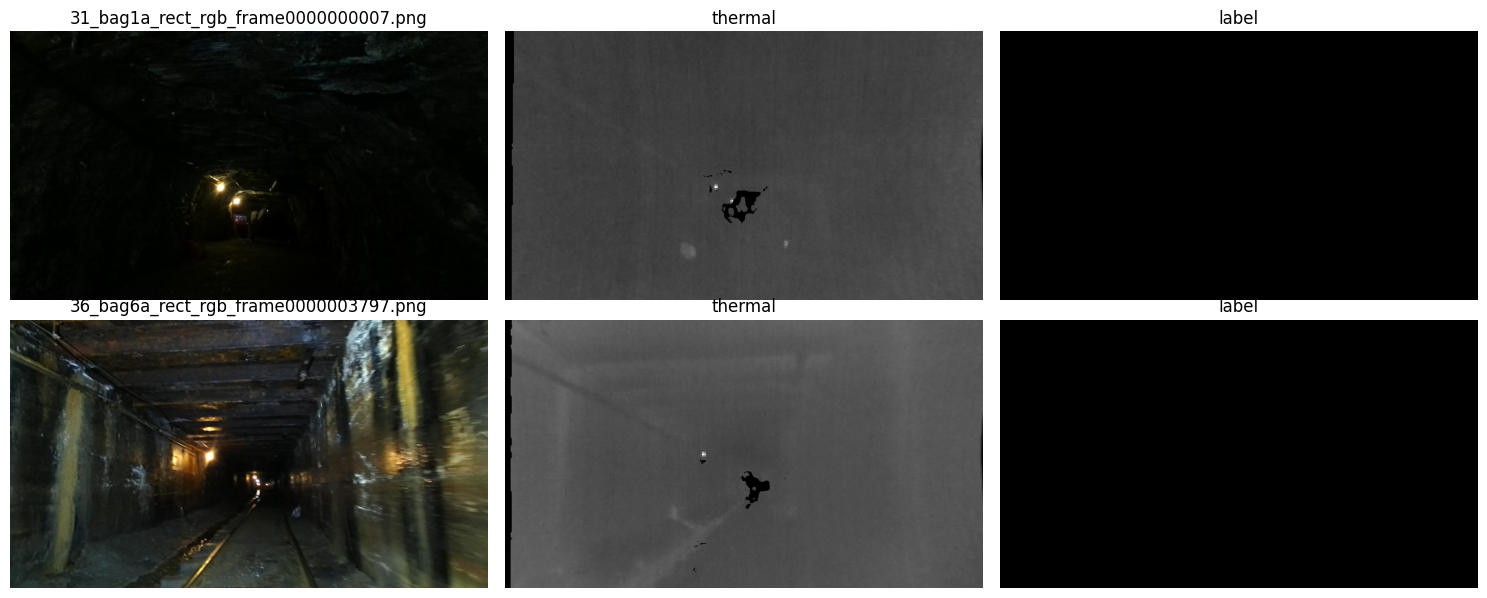

In [7]:
# ==========================================
# CELL 6: Visual Check of PST900 + Label Values
# ==========================================
import importlib
import matplotlib.pyplot as plt
sys.path.insert(0, WORKSPACE)
import rgbt_eval, cmrf_engine
importlib.reload(rgbt_eval); importlib.reload(cmrf_engine)
from rgbt_eval import *

inspect_dataset(PST_ROOT, "train")
ds_vis = PST900Dataset(PST_ROOT, "train")
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for r, i in enumerate([0, len(ds_vis) // 2]):
    rgb, th, lab, name = ds_vis.load_raw(i)
    ax[r, 0].imshow(rgb); ax[r, 0].set_title(name[:40])
    ax[r, 1].imshow(th, cmap="gray"); ax[r, 1].set_title("thermal")
    ax[r, 2].imshow(colorize(lab)); ax[r, 2].set_title("label")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.show()


In [8]:
# ==========================================
# CELL 7: Configure: CMRF patch, validation split, run settings
# ==========================================
import json

# ---- 1. insert CMRF into the official CMX encoder (does nothing for E1 / CONTROL) ----
cmrf_engine.patch_cmx(REPO_DIR)
CMRF_CFG = cmrf_engine.write_cmrf_config(REPO_DIR, stages=SETTINGS["cmrf_stages"],
                                         reduction=4, lam=0.1, init_scale=0.1)
print("CMRF config:", CMRF_CFG)

# ---- 2. validation set ----
# PST900 has no validation split. Using the TEST set to pick the best epoch would be test-set leakage,
# so ~15% of the TRAIN images are held out, split by recording ('bagNN') so near-identical frames
# never appear in both. The split is saved in Drive once and reused by every experiment and every resume.
split = cmrf_engine.make_val_split(PST_ROOT, SPLIT_JSON, frac=0.15)
print(f"Validation split ({split['by']}): train {len(split['train'])} | val {len(split['val'])} | "
      f"val recordings {split['val_recordings']}")

# ---- 3. training settings (CMX defaults: AdamW 6e-5, wd 0.01, poly 0.9, 10 warm-up epochs) ----
RUN = dict(
    name=RUN_NAME, repo=REPO_DIR, toolkit_dir=WORKSPACE, pretrained=MIT_B2, backbone="mit_b2",
    pst_root=PST_ROOT, split_json=SPLIT_JSON, ckpt_dir=CKPT_DIR,
    val_mode="holdout",          # 'holdout' (recommended) or 'test' (leaks the test set into model selection)
    epochs=100, snapshot_every=10, warmup_epochs=10,
    batch_size=4, crop=[480, 640], val_size=[480, 640],
    lr=6e-5, weight_decay=0.01, amp=True, num_workers=2, seed=0,
    corruption_p=SETTINGS["corruption_p"],
)
RUN_JSON = os.path.join(CKPT_DIR, "run_config.json")
if os.path.exists(RUN_JSON):              # a resumed run must keep its original settings
    old = json.load(open(RUN_JSON))
    diff = {k: (old.get(k), v) for k, v in RUN.items()
            if k not in ("repo", "toolkit_dir", "pretrained", "pst_root") and old.get(k) != v}
    assert not diff, f"Settings changed since this run started: {diff}. Restore them or use another EXPERIMENT."
json.dump(RUN, open(RUN_JSON, "w"), indent=2)

# ---- 4. quick model check ----
_m = cmrf_engine.build_model(REPO_DIR, pretrained=MIT_B2)
groups, n_extra = cmrf_engine.param_groups(_m, RUN["lr"], RUN["weight_decay"])
n_opt = sum(p.numel() for g in groups for p in g["params"])
n_all = sum(p.numel() for p in _m.parameters())
assert n_opt == n_all, "some parameters are missing from the optimizer"
p_cmrf = sum(p.numel() for p in _m.backbone.CMRFs.parameters()) / 1e6
print(f"Model: {n_all/1e6:.2f} M params | CMRF {p_cmrf:.3f} M | stages {list(_m.backbone.CMRFs.keys()) or 'none'} | "
      f"all {n_all:,} parameters are in the optimizer (incl. {n_extra} CMRF scale parameters)")
del _m


CMRF config: {'stages': [3], 'reduction': 4, 'lambda': 0.1, 'init_scale': 0.1}
Validation split (recording): train 491 | val 106 | val recordings ['bag19', 'bag6', 'bag8']


10 04:35:01 Using backbone: Segformer-B2
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
10 04:35:12 Using MLP Decoder
10 04:35:12 Loading pretrained model: /content/CMX_PST900_Workspace/pretrained/mit_b2.pth
10 04:35:12 Load model, Time usage:
	IO: 0.3831791877746582, initialize parameters: 0.04846811294555664
10 04:35:12 Initing weights ...


Model: 67.03 M params | CMRF 0.468 M | stages ['3'] | all 67,031,631 parameters are in the optimizer (incl. 2 CMRF scale parameters)


In [9]:
# ==========================================
# CELL 8: Launch Training (resumable)
# ==========================================
# Stop this cell whenever you like. Run all cells again later: it continues from the last finished epoch.
# After EVERY epoch:   last.pth (resume point) | best_model.pth if validation loss improved
# Every 10 epochs:     epoch_10.pth, epoch_20.pth, ...
import re
import threading
import logging
from google.colab import auth
from googleapiclient.discovery import build
logging.getLogger("google_auth_httplib2").setLevel(logging.ERROR)

auth.authenticate_user()   # first run: click Allow (needed to empty old checkpoints out of the Drive trash)

# Overwriting a file in Drive moves the old copy to the trash, which still counts against your 15 GB.
# Only trashed copies of OUR checkpoint files are deleted (permanently); nothing else in the trash is touched.
TRASH_QUERY = ("trashed = true and (name = 'last.pth' or name = 'best_model.pth' or name contains 'epoch_' "
               "or name contains '.pth.tmp')")
OURS = re.compile(r"^(last|best_model|epoch_\d+)\.pth(\.tmp)?$")

def purge_trash():
    service = build("drive", "v3", cache_discovery=False)
    removed, freed, token = 0, 0, None
    while True:
        resp = service.files().list(q=TRASH_QUERY, spaces="drive", pageSize=100, pageToken=token,
                                    fields="nextPageToken, files(id, name, size)").execute()
        for f in resp.get("files", []):
            if not OURS.match(f["name"]):
                continue
            try:
                service.files().delete(fileId=f["id"]).execute()
                removed += 1; freed += int(f.get("size", 0))
            except Exception as e:
                print(f"[trash cleaner] could not delete {f.get('name')}: {e}")
        token = resp.get("nextPageToken")
        if not token:
            break
    return removed, freed

def purge_loop(stop_evt, every_sec=1200):
    while not stop_evt.is_set():
        try:
            purge_trash()
        except Exception as e:
            print(f"[trash cleaner] error: {e}")
        stop_evt.wait(every_sec)

if "purge_stop" in globals():
    purge_stop.set()
purge_stop = threading.Event()
threading.Thread(target=purge_loop, args=(purge_stop,), daemon=True).start()
n, b = purge_trash()
print(f"[trash cleaner] permanently deleted {n} old checkpoint file(s), freed {b / 1e9:.2f} GB")

%cd {WORKSPACE}
!python -u cmrf_engine.py {RUN_JSON}

n, b = purge_trash()
print(f"[trash cleaner] final cleanup: deleted {n} file(s), freed {b / 1e9:.2f} GB")
print("Files in", CKPT_DIR, ":", sorted(os.listdir(CKPT_DIR)))


[trash cleaner] permanently deleted 0 old checkpoint file(s), freed 0.00 GB
/content
10 04:35:38 Using backbone: Segformer-B2
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
10 04:35:44 Using MLP Decoder
10 04:35:44 Loading pretrained model: /content/CMX_PST900_Workspace/pretrained/mit_b2.pth
10 04:35:44 Load model, Time usage:
	IO: 0.0933997631072998, initialize parameters: 0.04723834991455078
10 04:35:44 Initing weights ...
[Resume] from /content/drive/MyDrive/AIProj_CMX/runs/E2v2_cmx_b2_ep100/last.pth: continuing at epoch 101 (best val loss 0.0099 @ epoch 72)
[Run] E2v2_cmx_b2_ep100 | CMRF stages ['3'] | corruption p=0.0 | train 491 | val 106 (holdout) | 122 it/epoch | AMP True | extra params added to optimizer: 2
Training already complete (100 epochs).
[trash cleaner] final cleanup: deleted 0 file(s), freed 0.00 GB
Files in /content/drive/MyDrive/

10 04:36:02 NumExpr defaulting to 2 threads.


Epochs finished: 100/100 | best (lowest validation loss): epoch 72, val loss 0.0099, val mIoU 84.12


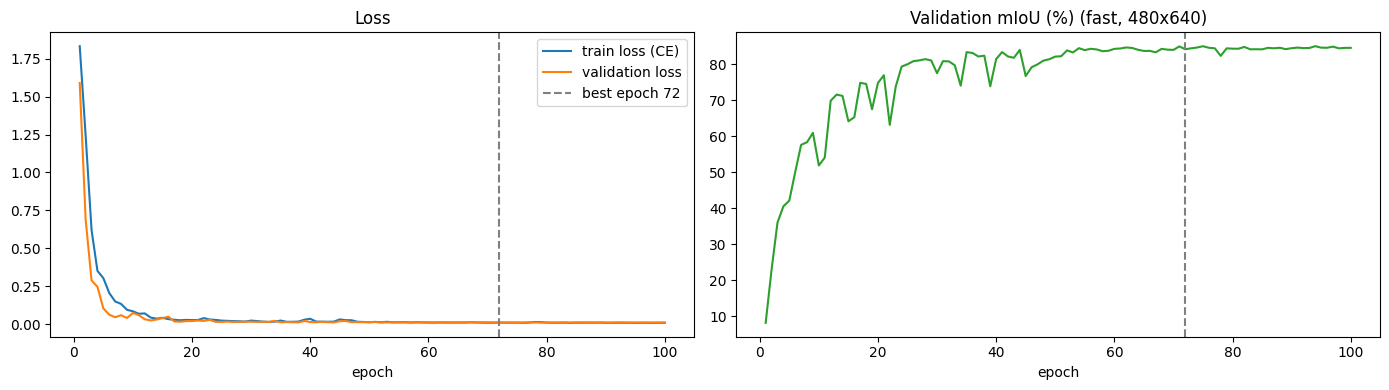

In [10]:
# ==========================================
# CELL 9: Training Curves & Best Epoch
# ==========================================
import pandas as pd
log = pd.read_csv(os.path.join(CKPT_DIR, "train_log.csv")).drop_duplicates("epoch", keep="last")
best = log.loc[log.val_loss.idxmin()]
print(f"Epochs finished: {int(log.epoch.max())}/{RUN['epochs']} | "
      f"best (lowest validation loss): epoch {int(best.epoch)}, val loss {best.val_loss:.4f}, val mIoU {best.val_mIoU:.2f}")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(log.epoch, log.train_ce, label="train loss (CE)")
ax[0].plot(log.epoch, log.val_loss, label="validation loss")
ax[0].axvline(best.epoch, ls="--", c="gray", label=f"best epoch {int(best.epoch)}")
ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("Loss")
ax[1].plot(log.epoch, log.val_mIoU, c="tab:green"); ax[1].axvline(best.epoch, ls="--", c="gray")
ax[1].set_xlabel("epoch"); ax[1].set_title("Validation mIoU (%) (fast, 480x640)")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, f"{RUN_NAME}_curves.png"), dpi=120); plt.show()


In [11]:
# ==========================================
# CELL 10: Evaluation on the Test Set (mIoU, Dice, Sensitivity, Specificity + robustness)
# ==========================================
# Model selection = lowest validation loss (best_model.pth), as agreed with the supervisor.
# Protocol identical to E1/E2: sliding window 480x640, stride 2/3, full-resolution 720x1280 labels.
# The full benchmark (clean + 7 corruptions x 3 severities) takes about 30-40 min on a T4.
from tabulate import tabulate
EVAL_CKPT      = "best_model.pth"     # or "last.pth", "epoch_50.pth", ...
RUN_ROBUSTNESS = True                 # False = clean test set only (about 2 min)

device = torch.device("cuda")
model = cmrf_engine.build_model(REPO_DIR)
ck = cmrf_engine.load_weights(model, os.path.join(CKPT_DIR, EVAL_CKPT))
model = model.to(device).eval()
print(f"Evaluating {EVAL_CKPT} (epoch {ck.get('epoch')})")
TAG = f"{EXPERIMENT}@{EVAL_CKPT.replace('.pth', '')}"
bench_csv = os.path.join(RESULTS_DIR, "benchmark.csv")
rows = run_benchmark(model, PST_ROOT, corruptions=None if RUN_ROBUSTNESS else [], crop=(480, 640),
                     stride_rate=2/3, flip=False, channel_order="BGR", out_csv=bench_csv, tag=TAG)

clean = rows[0]
per_class = pd.DataFrame({m: [clean[f"{m}/{c}"] * 100 for c in PST900_CLASSES]
                          for m in ("IoU", "Dice", "Sensitivity", "Specificity")}, index=PST900_CLASSES)
per_class.loc["mean (all 5)"] = [clean[k] * 100 for k in ("mIoU", "mDice", "mSensitivity", "mSpecificity")]
per_class.loc["mean (4 objects)"] = [clean[k] * 100 for k in ("mIoU_obj", "mDice_obj", "mSensitivity_obj", "mSpecificity_obj")]
per_class.to_csv(os.path.join(RESULTS_DIR, f"{RUN_NAME}_per_class_clean.csv"))
print("\nClean test set (%)")
print(tabulate(per_class.round(2), headers="keys", tablefmt="github"))

if RUN_ROBUSTNESS:
    df = pd.DataFrame(rows)
    rob = df[df.condition != "clean"].pivot(index="condition", columns="severity", values="mIoU").mul(100)
    rob["avg"] = rob.mean(1)
    rob.to_csv(os.path.join(RESULTS_DIR, f"{RUN_NAME}_robustness_mIoU.csv"))
    print("\nmIoU (%) under degradation of ONE camera")
    print(tabulate(rob.round(2), headers="keys", tablefmt="github"))
    s = robustness_summary(rows)
    print("\n" + tabulate([[k, round(v * 100, 2)] for k, v in s.items()], headers=["summary", "%"], tablefmt="github"))


10 04:36:03 Using backbone: Segformer-B2
10 04:36:05 Using MLP Decoder
10 04:36:05 Initing weights ...


Evaluating best_model.pth (epoch 72)
E2v2@best_model              clean s0 | mIoU  85.34 | mDice  91.84 | mSens  89.27 | mSpec  97.56 | mIoU(obj)  81.78
E2v2@best_model      rgb_low_light s1 | mIoU  77.98 | mDice  87.24 | mSens  80.23 | mSpec  95.28 | mIoU(obj)  72.67
E2v2@best_model      rgb_low_light s2 | mIoU  34.88 | mDice  45.21 | mSens  35.83 | mSpec  83.38 | mIoU(obj)  19.19
E2v2@best_model      rgb_low_light s3 | mIoU  19.44 | mDice  19.71 | mSens  20.00 | mSpec  80.00 | mIoU(obj)   0.00
E2v2@best_model          rgb_noise s1 | mIoU  85.52 | mDice  92.00 | mSens  89.94 | mSpec  97.70 | mIoU(obj)  82.02
E2v2@best_model          rgb_noise s2 | mIoU  82.52 | mDice  90.18 | mSens  86.96 | mSpec  96.85 | mIoU(obj)  78.30
E2v2@best_model          rgb_noise s3 | mIoU  75.95 | mDice  85.87 | mSens  80.43 | mSpec  95.02 | mIoU(obj)  70.15
E2v2@best_model           rgb_blur s1 | mIoU  80.87 | mDice  88.90 | mSens  85.84 | mSpec  96.97 | mIoU(obj)  76.23
E2v2@best_model           rgb_blur 

In [12]:
# ==========================================
# CELL 11: Cost + Comparison with E1 / first E2 run
# ==========================================
cost = model_cost(model, input_size=(480, 640))
print(tabulate([[k, v] for k, v in cost.items()], headers=["cost", RUN_NAME], tablefmt="github"))

# Reference numbers from the earlier runs (official train.py, all 597 training images, last epoch).
# Note: this run trains on the held-out-split train set, so for a strictly fair comparison
# also run EXPERIMENT = 'E1' with this notebook.
REF = {
    "E1 (CMX)":     dict(mIoU=86.12, mIoU_obj=82.76, survivor=78.78, rgb_avg=67.42, thermal_avg=85.53, lowlight3=19.57),
    "E2 (1st run)": dict(mIoU=82.92, mIoU_obj=78.77, survivor=72.43, rgb_avg=63.90, thermal_avg=82.49, lowlight3=19.44),
}
cur = dict(mIoU=clean["mIoU"] * 100, mIoU_obj=clean["mIoU_obj"] * 100, survivor=clean["IoU/Survivor"] * 100)
if RUN_ROBUSTNESS:
    cur.update(rgb_avg=rob[rob.index.str.startswith("rgb")]["avg"].mean(),
               thermal_avg=rob[rob.index.str.startswith("thermal")]["avg"].mean(),
               lowlight3=rob.loc["rgb_low_light", 3])
comp = pd.DataFrame({**REF, RUN_NAME: cur}).T
comp.columns = ["clean mIoU", "objects mIoU", "Survivor IoU", "avg RGB-degraded", "avg thermal-degraded", "RGB low-light s3"][:len(comp.columns)]
comp.to_csv(os.path.join(RESULTS_DIR, f"{RUN_NAME}_vs_E1_E2.csv"))
print(tabulate(comp.round(2), headers="keys", tablefmt="github"))


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


| cost       |   E2v2_cmx_b2_ep100 |
|------------|---------------------|
| params_M   |            67.0316  |
| GFLOPs     |            78.8351  |
| latency_ms |           106.527   |
| FPS        |             9.38729 |
|                   |   clean mIoU |   objects mIoU |   Survivor IoU |   avg RGB-degraded |   avg thermal-degraded |   RGB low-light s3 |
|-------------------|--------------|----------------|----------------|--------------------|------------------------|--------------------|
| E1 (CMX)          |        86.12 |          82.76 |          78.78 |              67.42 |                  85.53 |              19.57 |
| E2 (1st run)      |        82.92 |          78.77 |          72.43 |              63.9  |                  82.49 |              19.44 |
| E2v2_cmx_b2_ep100 |        85.34 |          81.78 |          72.46 |              60.4  |                  83.39 |              19.44 |


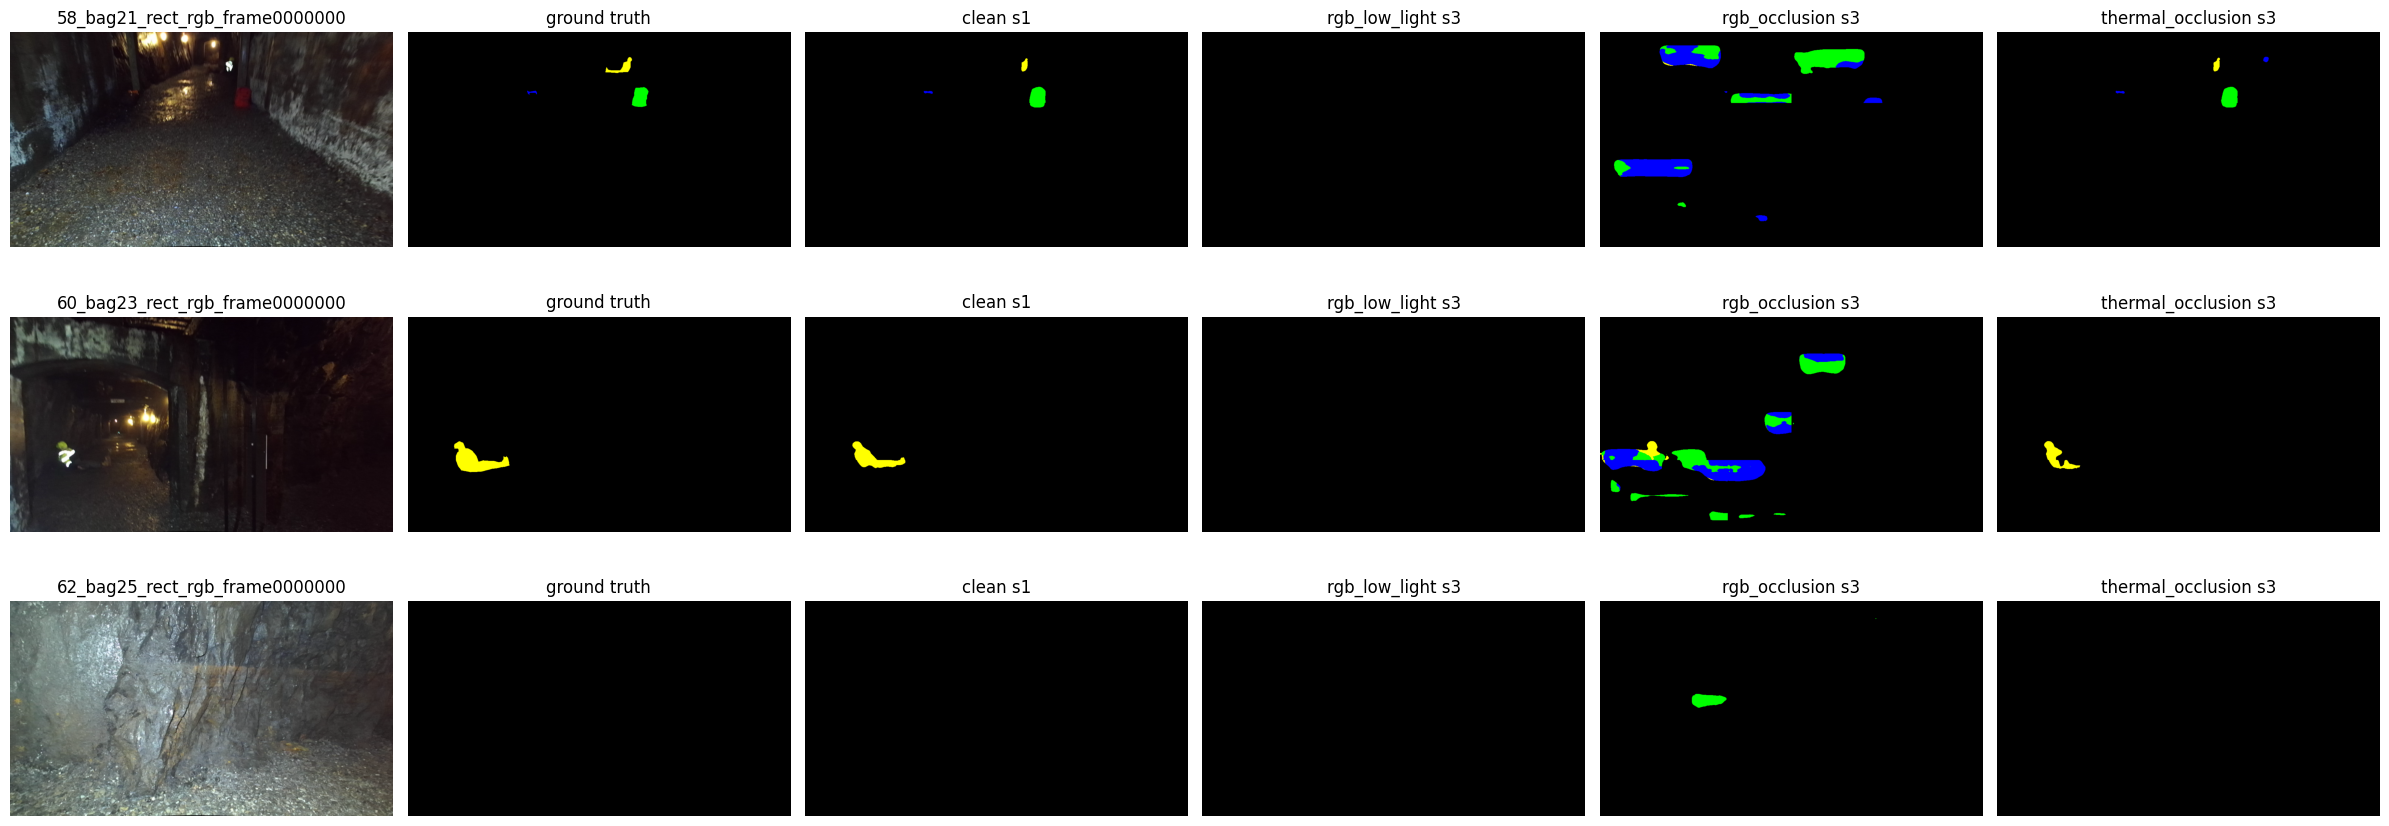

| input         |   mIoU |   objects mIoU |
|---------------|--------|----------------|
| RGB + thermal |  85.34 |          81.78 |
| RGB only      |  81.22 |          76.68 |
| thermal only  |  19.44 |           0    |
learned residual strength: scale_t 0.0923 | scale_r 0.1023 (start 0.1)


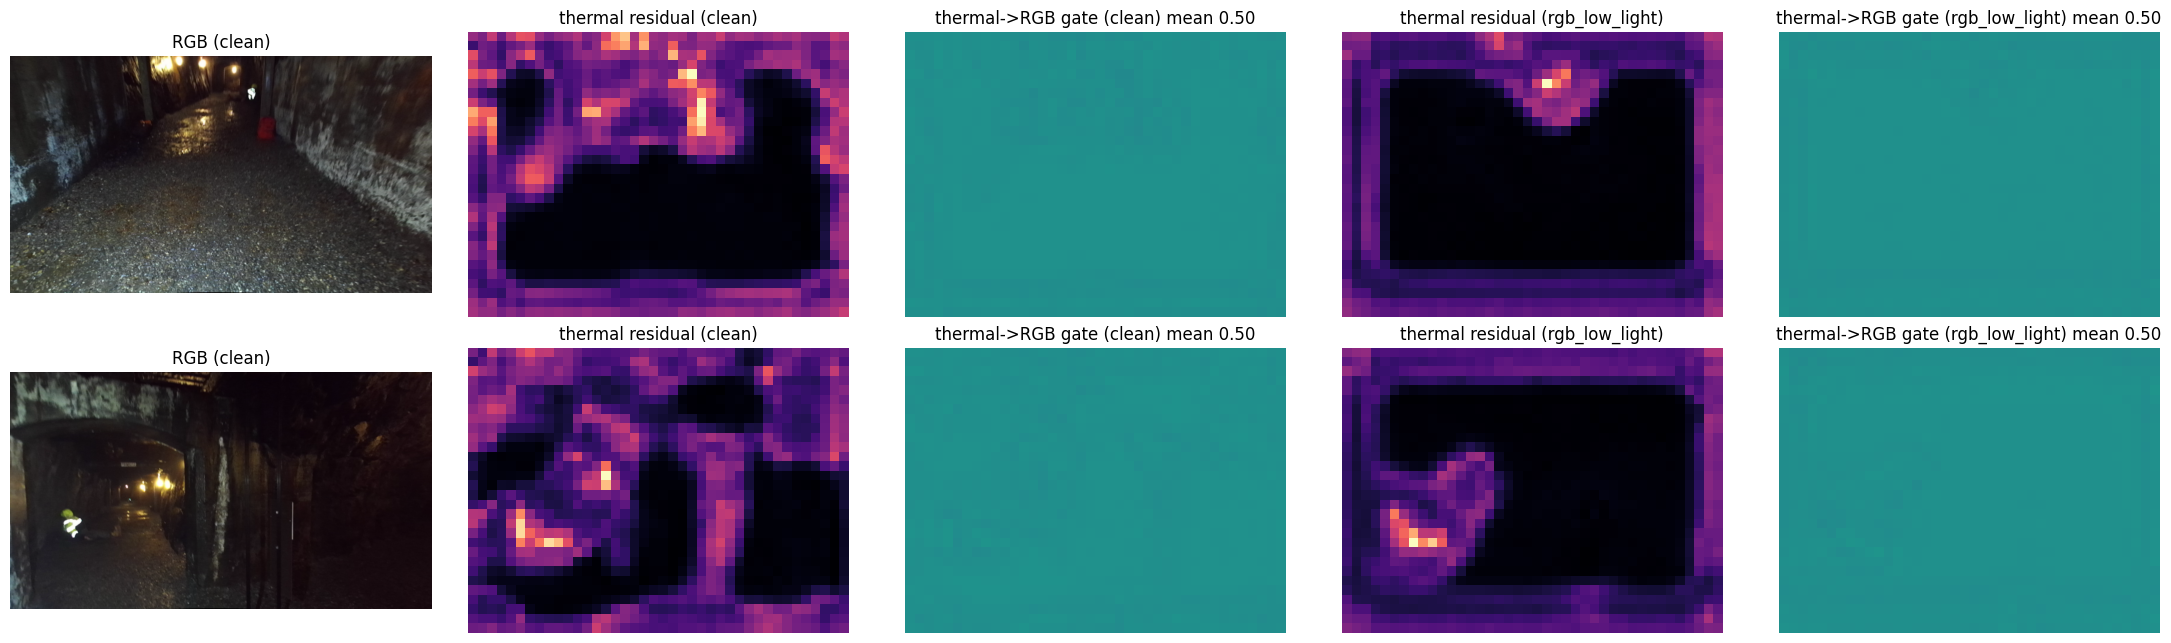

In [13]:
# ==========================================
# CELL 12: Visual Inference, Modality Drop, CMRF Gate Maps
# ==========================================
import torch.nn.functional as F

# ---- 12a. predictions under degradation ----
SHOW = [("clean", 1), ("rgb_low_light", 3), ("rgb_occlusion", 3), ("thermal_occlusion", 3)]
n_test = len(PST900Dataset(PST_ROOT, "test"))
idxs = [min(i, n_test - 1) for i in (3, 100, 200)]
fig, ax = plt.subplots(len(idxs), 2 + len(SHOW), figsize=(4 * (2 + len(SHOW)), 3 * len(idxs)))
for r, i in enumerate(idxs):
    for c, (cn, sev) in enumerate(SHOW):
        d = PST900Dataset(PST_ROOT, "test", corruption=cn, severity=sev, channel_order="BGR")
        b = d[i]
        with torch.no_grad():
            p = predict_probs(model, b["rgb"][None].to(device), b["thermal"][None].to(device)).argmax(1)[0].cpu().numpy()
        if c == 0:
            raw = d.load_raw(i)
            ax[r, 0].imshow(raw[0]); ax[r, 0].set_title(raw[3][:30])
            ax[r, 1].imshow(colorize(raw[2])); ax[r, 1].set_title("ground truth")
        ax[r, 2 + c].imshow(colorize(p)); ax[r, 2 + c].set_title(f"{cn} s{sev}")
for a in ax.flat: a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, f"{RUN_NAME}_qualitative.png"), dpi=110); plt.show()

# ---- 12b. modality drop: how much does the model rely on each camera? ----
drop = [{"input": "RGB + thermal", "mIoU": clean["mIoU"] * 100, "objects mIoU": clean["mIoU_obj"] * 100}]
for name, fwd in [("RGB only", lambda m, r, t: m(r, torch.zeros_like(t))),
                  ("thermal only", lambda m, r, t: m(torch.zeros_like(r), t))]:
    rr = run_benchmark(model, PST_ROOT, forward_fn=fwd, corruptions=[], crop=(480, 640), channel_order="BGR",
                       out_csv=os.path.join(RESULTS_DIR, "modality_drop.csv"), tag=f"{TAG}_{name.replace(' ', '_')}",
                       verbose=False)[0]
    drop.append({"input": name, "mIoU": rr["mIoU"] * 100, "objects mIoU": rr["mIoU_obj"] * 100})
print(tabulate(pd.DataFrame(drop).round(2), headers="keys", tablefmt="github", showindex=False))

# ---- 12c. what CMRF does (only for experiments with CMRF) ----
if len(model.backbone.CMRFs):
    cm = model.backbone.CMRFs[str(SETTINGS["cmrf_stages"][0])]
    print(f"learned residual strength: scale_t {cm.scale_t.item():.4f} | scale_r {cm.scale_r.item():.4f} (start 0.1)")
    fig, ax = plt.subplots(2, 5, figsize=(22, 6.5))
    for r, i in enumerate(idxs[:2]):
        for c, (cn, sev) in enumerate([("clean", 1), ("rgb_low_light", 3)]):
            b = PST900Dataset(PST_ROOT, "test", corruption=cn, severity=sev, channel_order="BGR")[i]
            rgb = F.interpolate(b["rgb"][None], size=(480, 640), mode="bilinear", align_corners=False).to(device)
            th = F.interpolate(b["thermal"][None], size=(480, 640), mode="bilinear", align_corners=False).to(device)
            with torch.no_grad():
                model(rgb, th)
            ax[r, 1 + 2 * c].imshow(cm.last["res_t"][0].cpu(), cmap="magma"); ax[r, 1 + 2 * c].set_title(f"thermal residual ({cn})")
            ax[r, 2 + 2 * c].imshow(cm.last["gate_t"][0].cpu(), cmap="viridis", vmin=0, vmax=1)
            ax[r, 2 + 2 * c].set_title(f"thermal->RGB gate ({cn}) mean {cm.last['gate_t'].mean():.2f}")
        ax[r, 0].imshow(PST900Dataset(PST_ROOT, "test").load_raw(i)[0]); ax[r, 0].set_title("RGB (clean)")
    for a in ax.flat: a.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, f"{RUN_NAME}_cmrf_maps.png"), dpi=110); plt.show()


In [14]:
# ==========================================
# CELL 13: (Optional) Clean mIoU of every 10-epoch snapshot
# ==========================================
# Shows how test accuracy develops over training (about 2 min per snapshot). Not used for model selection.
RUN_SNAPSHOT_EVAL = False
if RUN_SNAPSHOT_EVAL:
    snap_rows = []
    for ep in range(RUN["snapshot_every"], RUN["epochs"] + 1, RUN["snapshot_every"]):
        p = os.path.join(CKPT_DIR, f"epoch_{ep}.pth")
        if not os.path.exists(p):
            continue
        cmrf_engine.load_weights(model, p)
        r0 = run_benchmark(model.eval(), PST_ROOT, corruptions=[], channel_order="BGR", verbose=False)[0]
        snap_rows.append([ep, r0["mIoU"] * 100, r0["mIoU_obj"] * 100, r0["mDice"] * 100,
                          r0["mSensitivity"] * 100, r0["mSpecificity"] * 100])
    snap = pd.DataFrame(snap_rows, columns=["epoch", "mIoU", "objects mIoU", "mDice", "mSens", "mSpec"])
    snap.to_csv(os.path.join(RESULTS_DIR, f"{RUN_NAME}_snapshots_clean.csv"), index=False)
    print(tabulate(snap.round(2), headers="keys", tablefmt="github", showindex=False))
    cmrf_engine.load_weights(model, os.path.join(CKPT_DIR, EVAL_CKPT))   # back to the selected model


In [15]:
# ==========================================
# CELL 14: Package Results (zip in Drive + download)
# ==========================================
pkg = f"/content/{RUN_NAME}_results"
shutil.rmtree(pkg, ignore_errors=True); os.makedirs(pkg)
for f in glob.glob(f"{RESULTS_DIR}/*") + [os.path.join(CKPT_DIR, x) for x in ("train_log.csv", "run_config.json")] + [SPLIT_JSON]:
    if os.path.isfile(f):
        shutil.copy(f, pkg)
zip_path = shutil.make_archive(os.path.join(DRIVE_ROOT, f"{RUN_NAME}_results"), "zip", pkg)
print("Saved:", zip_path, "| contents:", sorted(os.listdir(pkg)))
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("Automatic download skipped:", e)


Saved: /content/drive/MyDrive/AIProj_CMX/E2v2_cmx_b2_ep100_results.zip | contents: ['E2v2_cmx_b2_ep100_cmrf_maps.png', 'E2v2_cmx_b2_ep100_curves.png', 'E2v2_cmx_b2_ep100_per_class_clean.csv', 'E2v2_cmx_b2_ep100_qualitative.png', 'E2v2_cmx_b2_ep100_robustness_mIoU.csv', 'E2v2_cmx_b2_ep100_vs_E1_E2.csv', 'benchmark.csv', 'modality_drop.csv', 'run_config.json', 'train_log.csv', 'val_split.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>